In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import OneHotEncoder, RobustScaler

In [2]:
url = "https://raw.githubusercontent.com/datasciencedojo/datasets/refs/heads/master/titanic.csv"
df = pd.read_csv(url)

df = df.drop(columns=['PassengerId', 'Name', 'Ticket', 'Cabin'])

X = df.drop("Survived", axis=1)
y = df["Survived"]

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=42
)
X_train = X_train.reset_index(drop=True)
X_test = X_test.reset_index(drop=True)

age_mean = X_train["Age"].mean()
X_train["Age"] = X_train["Age"].fillna(age_mean)
X_test["Age"] = X_test["Age"].fillna(age_mean)

embarked_mode = X_train["Embarked"].mode()[0]
X_train["Embarked"] = X_train["Embarked"].fillna(embarked_mode)
X_test["Embarked"] = X_test["Embarked"].fillna(embarked_mode)

fare_median = X_train["Fare"].median()
X_train["Fare"] = X_train["Fare"].fillna(fare_median)
X_test["Fare"] = X_test["Fare"].fillna(fare_median)

In [4]:
for column in ["Pclass", "Sex", "Embarked"]:
    encoder = OneHotEncoder(sparse_output=False, handle_unknown="ignore")
    encoder.fit(X_train[[column]])
    
    train_encoded = pd.DataFrame(encoder.transform(X_train[[column]]), 
                                 columns=encoder.get_feature_names_out([column]))
    test_encoded = pd.DataFrame(encoder.transform(X_test[[column]]), 
                                columns=encoder.get_feature_names_out([column]))
    
    X_train = pd.concat([X_train.drop(columns=[column]), train_encoded], axis=1)
    X_test = pd.concat([X_test.drop(columns=[column]), test_encoded], axis=1)

for col in ["Age", "SibSp", "Parch", "Fare"]:
    scaler = RobustScaler()
    X_train[col] = scaler.fit_transform(X_train[[col]])
    X_test[col] = scaler.transform(X_test[[col]])

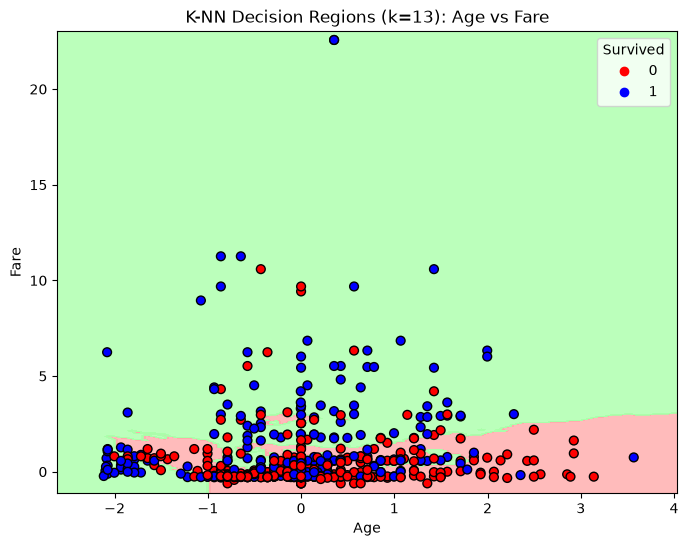

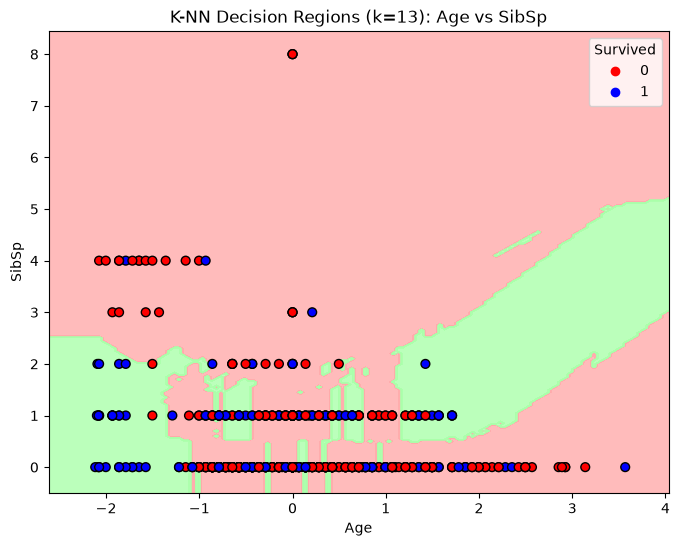

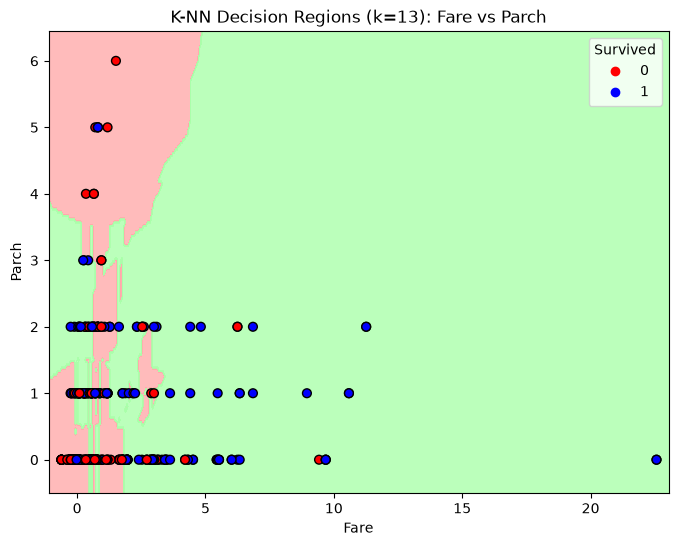

In [5]:
parejas = [
    ("Age", "Fare"),
    ("Age", "SibSp"),
    ("Fare", "Parch")
]

k_vecinos = 13
cmap_light = ListedColormap(['#FFAAAA', '#AAFFAA'])
cmap_bold = ["red", "blue"]

for var1, var2 in parejas:
    X_pair = X_train[[var1, var2]].values
    y_target = y_train.values
    
    knn = KNeighborsClassifier(n_neighbors=k_vecinos)
    knn.fit(X_pair, y_target)
    
    x_min, x_max = X_pair[:, 0].min() - 0.5, X_pair[:, 0].max() + 0.5
    y_min, y_max = X_pair[:, 1].min() - 0.5, X_pair[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.05),
                         np.arange(y_min, y_max, 0.05))
    
    y_predict = knn.predict(np.c_[xx.ravel(), yy.ravel()])
    y_predict = y_predict.reshape(xx.shape)
    
    plt.figure(figsize=(8, 6))
    plt.contourf(xx, yy, y_predict, cmap=cmap_light, alpha=0.8)
    
    scatter = plt.scatter(X_pair[:, 0], X_pair[:, 1], c=y_target,
                          cmap=ListedColormap(cmap_bold),
                          edgecolor='black', s=40)
    
    plt.title(f"K-NN Decision Regions (k={k_vecinos}): {var1} vs {var2}")
    plt.xlabel(var1)
    plt.ylabel(var2)
    plt.legend(*scatter.legend_elements(), title="Survived")
    plt.show()